<a href="https://colab.research.google.com/github/OwenLoughery/Project3-Wine_Reviews/blob/main/4401_Project_3_EDA_Stanley.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Introduction
I will be examining batch 2 which consists of Chardonnay, 	Sparkling, Sangiovese, 	White Blend (generic), 	Aromatic Whites and 	Fortified & Dessert. This first part of the project will be primarily exploratory data analysis (EDA). I will explore these style of wine and report back any interesting findings.

##Pre-Processing

In [ ]:
!pip -q install nltk pandas pyarrow tqdm

import pandas as pd
import os
import re
import nltk

from tqdm.auto import tqdm
from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

tqdm.pandas()

for pkg in ["punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

LEMMATIZER = WordNetLemmatizer()

CSV_PATH = "/content/winemag-data-130k-v2.csv"
OUTPUT_PATH = "/content/processed_reviews.parquet"

In [ ]:
# Common words shared among wines
WINE_WORDS = {
    "wine", "flavor", "palate",
    "drink", "note", "show"
}

# Words to preserve
KEEP = {
    "red", "white", "apple", "blend", "style",
    "other", "de", "di", "del", "la",
    "black", "orange", "melon", "vital",
    "grain", "diamond", "mission", "du",
    "sparkling", "champagne", "port"
}

# Grape nicknames and masking placeholders
NICKNAMES = {
    "cab", "zin", "chard", "sauv",
    "gewürz", "gewurz", "grüner",
    "gruner", "varietyname"
}


def base_tokens(text):
    if pd.isna(text):
        return []

    english = set(stopwords.words("english"))

    tokens = word_tokenize(str(text).lower())

    return [
        LEMMATIZER.lemmatize(token)
        for token in tokens
        if token.isalpha() and token not in english
    ]


def name_words(names):
    """
    Convert variety names into individual tokens.
    """
    return {
        token
        for name in names.dropna()
        for token in base_tokens(name)
    }


def build_stopwords(df):
    """
    English stopwords + wine filler words +
    variety-name words + grape nicknames.
    """
    english = set(stopwords.words("english"))

    variety_words = name_words(df["variety"]) - KEEP

    all_stops = (
        english
        | WINE_WORDS
        | variety_words
        | NICKNAMES
    )

    return all_stops


def remove_stops(tokens, stops):
    """
    Remove stopwords from tokenized descriptions.
    """
    return [
        token
        for token in tokens
        if token not in stops
    ]


def leakage_report(df, col):
    """
    Percentage of reviews for each wine variety that
    contain words from their own variety name.
    """
    rates = {}

    for variety, sub in df.groupby("variety"):

        own_words = name_words(pd.Series([variety])) - KEEP

        leakage = sub[col].apply(
            lambda tokens: bool(
                own_words.intersection(tokens)
            )
        )

        rates[variety] = round(
            leakage.mean() * 100,
            1
        )

    return pd.Series(rates, name=col)

In [ ]:
def process():

    # ----------------------------
    # Load dataset
    # ----------------------------
    try:
        df = pd.read_csv(CSV_PATH, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(CSV_PATH, encoding="cp1252")

    # Remove reviews without descriptions or varieties
    df = df.dropna(
        subset=["description", "variety"]
    ).copy()

    print(f"Loaded {len(df):,} wine reviews")
    print(f"Unique varieties: {df['variety'].nunique()}")

    # ----------------------------
    # Mask variety names
    # ----------------------------
    print("\nMasking variety names...")

    variety_names = df["variety"].dropna().unique()

    variety_names = sorted(
        variety_names,
        key=len,
        reverse=True
    )

    pattern = re.compile(
        r"(?<!\w)(?:" +
        "|".join(re.escape(v) for v in variety_names) +
        r")(?!\w)",
        flags=re.IGNORECASE
    )

    df["description_masked"] = (
        df["description"]
        .progress_apply(
            lambda text: pattern.sub("varietyname", text)
        )
    )

    # ----------------------------
    # Build stopwords
    # ----------------------------
    english = set(stopwords.words("english"))
    all_stops = build_stopwords(df)

    print(f"\nTotal stopwords: {len(all_stops):,}")

    # ----------------------------
    # Tokenize original reviews
    # ----------------------------
    print("\nTokenizing original descriptions...")

    df["tokens_raw"] = df["description"].progress_apply(
        lambda text: remove_stops(
            base_tokens(text),
            english
        )
    )

    # ----------------------------
    # Tokenize masked descriptions
    # ----------------------------
    print("\nTokenizing masked descriptions...")

    df["tokens"] = df["description_masked"].progress_apply(
        lambda text: remove_stops(
            base_tokens(text),
            all_stops
        )
    )

    # Convert tokens into text
    df["clean_text"] = df["tokens"].str.join(" ")

    # ----------------------------
    # Clean designations
    # ----------------------------
    print("\nCleaning designations...")

    df["clean_designation"] = (
        df["designation"]
        .fillna("")
        .progress_apply(
            lambda text: " ".join(
                remove_stops(
                    base_tokens(text),
                    all_stops
                )
            )
        )
    )

    # ----------------------------
    # Leakage analysis
    # ----------------------------
    print("\nCalculating variety-name leakage...")

    report = pd.concat(
        [
            leakage_report(df, "tokens_raw"),
            leakage_report(df, "tokens")
        ],
        axis=1
    )

    report = report.rename(
        columns={
            "tokens_raw": "Before Cleaning (%)",
            "tokens": "After Cleaning (%)"
        }
    )

    report = report.sort_values(
        "Before Cleaning (%)",
        ascending=False
    )

    display(report)

    # ----------------------------
    # Save processed dataset
    # ----------------------------
    df.to_parquet(
        OUTPUT_PATH,
        index=False
    )

    print(
        f"\nSaved {len(df):,} rows to {OUTPUT_PATH}"
    )

    return df, report

In [ ]:
df_processed, leakage_results = process()

Loaded 129,970 wine reviews
Unique varieties: 707

Masking variety names...


  0%|          | 0/129970 [00:00<?, ?it/s]


Total stopwords: 726

Tokenizing original descriptions...


  0%|          | 0/129970 [00:00<?, ?it/s]


Tokenizing masked descriptions...


...


Cleaning designations...


  0%|          | 0/129970 [00:00<?, ?it/s]


Calculating variety-name leakage...


,Before Cleaning (%),After Cleaning (%)
Albanello,100.0,0.0
Žilavka,100.0,0.0
Vranac,100.0,0.0
Albarossa,100.0,0.0
Bombino Bianco,100.0,0.0
...,...,...
Marawi,0.0,0.0
Mandilaria,0.0,0.0
Malvasia-Viura,0.0,0.0
Espadeiro,0.0,0.0



Saved 129,970 rows to /content/processed_reviews.parquet


In [ ]:
display(
    df_processed[
        [
            "variety",
            "description",
            "description_masked",
            "clean_text"
        ]
    ].sample(10, random_state=42)
)

,variety,description,description_masked,clean_text
77718,Chardonnay,"Possibly a little sweet, this is a soft, easyg...","Possibly a little sweet, this is a soft, easyg...",possibly little sweet soft easygoing marked cl...
67681,Rosé,"A soft, almost off dry wine that is full in th...","A soft, almost off dry wine that is full in th...",soft almost dry full mouth caramel spice well ...
69877,Verdejo-Viura,Generic white-fruit aromas of peach and apple ...,Generic white-fruit aromas of peach and variet...,generic aroma peach slightly pithy feel good i...
46544,Cabernet Sauvignon,This is the winery's best Nebula in years. Whi...,This is the winery's best Nebula in years. Whi...,winery best nebula year still little soft swee...
186,Pinot Noir,This is a very rich Pinot whose primary virtue...,This is a very rich Pinot whose primary virtue...,rich whose primary virtue fruit explodes delic...
73126,Chardonnay,"An unabashedly rich and luscious wine, this co...","An unabashedly rich and luscious wine, this co...",unabashedly rich luscious combine ripe fresh f...
26800,Pinot Noir,"This opens with a pleasing toasty aroma, follo...","This opens with a pleasing toasty aroma, follo...",open pleasing toasty aroma following deft touc...
80832,Chardonnay,"Made with 100% Chardonnay, this creamy sparkle...","Made with 100% varietyname, this creamy sparkl...",made creamy sparkler open aroma hawthorn peach...
86297,Cabernet Sauvignon,"Here's a good, everyday Cab if you're looking ...","Here's a good, everyday Cab if you're looking ...",good everyday looking bargain dry tannic earth...
56015,Rosé,"Made from low-yielding, 70-year-old vines, thi...","Made from low-yielding, 70-year-old vines, thi...",made vine dense structure ripe powerful obviou...


##Set up

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [ ]:
df = pd.read_csv('winemag-data-130k-v2.csv')

In [ ]:
df.shape

(129971, 14)

In [ ]:
df.head(5)

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [ ]:
df["variety"].unique()

array(['White Blend', 'Portuguese Red', 'Pinot Gris', 'Riesling',
       'Pinot Noir', 'Tempranillo-Merlot', 'Frappato', 'Gewürztraminer',
       'Cabernet Sauvignon', 'Nerello Mascalese', 'Chardonnay', 'Malbec',
       'Tempranillo Blend', 'Meritage', 'Red Blend', 'Merlot',
       "Nero d'Avola", 'Chenin Blanc', 'Gamay', 'Sauvignon Blanc',
       'Viognier-Chardonnay', 'Primitivo', 'Catarratto', 'Inzolia',
       'Petit Verdot', 'Monica', 'Bordeaux-style White Blend', 'Grillo',
       'Sangiovese', 'Cabernet Franc', 'Champagne Blend',
       'Bordeaux-style Red Blend', 'Aglianico', 'Petite Sirah',
       'Touriga Nacional', 'Carmenère', 'Albariño', 'Petit Manseng',
       'Rosé', 'Zinfandel', 'Vernaccia', 'Rosato', 'Grüner Veltliner',
       'Viognier', 'Vermentino', 'Grenache Blanc', 'Syrah', 'Nebbiolo',
       'Shiraz-Cabernet Sauvignon', 'Pinot Blanc', 'Alsace white blend',
       'Barbera', 'Rhône-style Red Blend', 'Portuguese White', 'Graciano',
       'Tannat-Cabernet', 'Sauvign

In [ ]:
from IPython.display import display

# Select 8 different wine varieties
sample_varieties = (
    df["variety"]
    .dropna()
    .drop_duplicates()
    .sample(n=8, random_state=42)
)

# Randomly select one review per variety
sample_reviews = (
    df[df["variety"].isin(sample_varieties)]
    .groupby("variety", group_keys=False)
    .sample(n=1, random_state=42)
    [["variety", "description"]]
    .reset_index(drop=True)
)

# Rename columns for presentation
sample_reviews.columns = ["Wine Variety", "Tasting Description"]

# Display formatted table with full descriptions
display(
    sample_reviews.style
    .set_properties(
        subset=["Tasting Description"],
        **{
            "white-space": "normal",
            "text-align": "left",
            "min-width": "450px",
            "max-width": "750px"
        }
    )
    .set_properties(
        subset=["Wine Variety"],
        **{
            "text-align": "left",
            "font-weight": "bold"
        }
    )
    .hide(axis="index")
)

Wine Variety,Tasting Description
Cerceal,"A wild, herbal, wood-aged wine, its acidity a fine foil to the richly perfumed fruit. Pears and sweet melon come together with the toast of the wood. At this stage, the wood dominates and needs a year to soften—then the result will be impressively food-friendly."
Dornfelder,"Vanilla and spice aromas lend confectionery notes to this soft, slightly syrupy red wine. Sweet and fleshy on the palate, it's light in alcohol and acidity. The finish is marked by fine but rigid tannins."
Hondarrabi Zuri,"Aromas of children's vitamins, corn stalk and white peach set up a lemony stony zesty palate with lemon and nectarine flavors. A stony crisp cleansing finish does the job while not faltering."
Mourvèdre-Syrah,"This McLaren Vale winery specializes in blends of Mediterranean varieties, and this is a fine example. It's 70% Mourvèdre and 30% Syrah, featuring plum, berry and cedary vanilla notes, plus a bit of meatiness on the nose. Richly textured on the palate, it finishes long."
Savagnin,"Ripe and full-bodied, this is a forward, fruity wine. It has pear and apricot flavors, showing rich fruitiness and full floral character. Perfumes come through strongly at the end."
Sparkling Blend,"There's a strong, nutty character to this bubbly, with accents of Granny Smith apple, toast and lemon rind citrus on the nose and mouth. The rich mouth is full and satisfying, but the alcohol is a bit warming on the close."
Uva di Troia,"Straightforward and easy-drinking, this delivers ripe black cherry, succulent raspberry, violet and a dash of white pepper. It's smooth, with round, polished tannins that support the juicy palate."
Zierfandler-Rotgipfler,"A restrained but lusciously ripe pear scent emanates from the deep, rounded and nutty core, supported by acidic verve."


In [ ]:
wine_styles = [
    # Chardonnay
    "Chardonnay", "Morillon",

    # Sparkling
    "Sparkling Blend", "Champagne Blend", "Glera", "Prosecco",
    "Portuguese Sparkling",

    # Sangiovese
    "Sangiovese", "Sangiovese Grosso", "Prugnolo Gentile",

    # White Blends
    "White Blend", "Chardonnay-Viognier", "Viognier-Chardonnay",
    "Sauvignon Blanc-Chardonnay", "Chardonnay-Sauvignon",
    "Chardonnay-Pinot Blanc", "Chardonnay-Sauvignon Blanc",
    "Pinot Blanc-Chardonnay", "Chardonnay Weissburgunder",
    "Chardonnay-Pinot Gris", "Chardonnay-Pinot Grigio",
    "Chardonnay-Riesling", "Pinot Grigio-Chardonnay",
    "Pinot Grigio-Sauvignon Blanc", "Riesling-Chardonnay",
    "Sauvignon Blanc-Sauvignon Gris",

    # Aromatic Whites
    "Gewürztraminer", "Moscato", "Torrontés", "Muscat",
    "Moscatel", "Malvasia", "Muscat Canelli", "Müller-Thurgau",
    "Moschofilero", "Traminer", "Gelber Muskateller", "Zibibbo",
    "Scheurebe", "Orange Muscat", "Kerner", "Malvasia Bianca",
    "Muskat Ottonel", "Moscato Giallo", "Muscat Blanc",
    "Black Muscat", "Moscadello", "Traminette", "Malagousia",
    "Malvasia Istriana", "Gewürztraminer-Riesling",
    "Moscatel Roxo", "Roter Traminer", "Malvasia Fina",
    "Symphony", "Muskateller", "Muscat Blanc à Petit Grain",
    "Muscat of Alexandria", "Muscat d'Alexandrie",
    "Muscat Hamburg", "Morio Muskat", "Malagouzia",
    "Moscatel de Alejandría", "Muscat Blanc à Petits Grains",
    "Muscatel", "Muskat", "Rivaner", "Siegerrebe",
    "Gelber Traminer", "Cserszegi Fűszeres", "Black Monukka",
    "Malvasia di Candia", "Moscatel Graúdo", "Moscato Rosa",
    "Orangetraube", "Rosenmuskateller", "Tămâioasă Românească",
    "Bukettraube", "Huxelrebe", "Irsai Oliver", "Malvazija",
    "Malvoisie", "Misket", "Moscato di Noto", "Moscofilero",
    "Pinot Gris-Gewürztraminer", "Silvaner-Traminer",
    "Torontel", "Valvin Muscat", "Viognier-Gewürztraminer",
    "Bacchus",

    # Fortified / Dessert Wines
    "Port", "Sherry", "Pedro Ximénez", "Tokaji", "Palomino",
    "Tokay", "Madeira Blend", "Bual", "Muscadel", "Cerceal",
    "Sercial", "White Port", "Tinta Negra Mole", "Malmsey",
    "St. George", "Cercial", "Terrantez"
]

df_filtered = df[df["variety"].isin(wine_styles)].copy()

print("Original rows:", len(df))
print("Filtered rows:", len(df_filtered))
print("Unique varieties:", df_filtered["variety"].nunique())

Original rows: 129971
Filtered rows: 25496
Unique varieties: 97


In [ ]:
missing_styles = set(wine_styles) - set(df["variety"].dropna())

print("Styles not found:")
print(sorted(missing_styles))

Styles not found:
['Bukettraube', 'Chardonnay-Pinot Grigio', 'Cserszegi Fűszeres', 'Huxelrebe', 'Malmsey', 'Malvazija', 'Malvoisie', 'Moscofilero', 'Muscat Blanc à Petit Grain', 'Pinot Grigio-Chardonnay', 'St. George']


In [ ]:
style_groups = {
    "Chardonnay": wine_styles[0:2],
    "Sparkling": wine_styles[2:7],
    "Sangiovese": wine_styles[7:10],
    "White Blend": wine_styles[10:26],
    "Aromatic White": wine_styles[26:-18],
    "Fortified/Dessert": wine_styles[-18:]
}

style_map = {
    style: group
    for group, styles in style_groups.items()
    for style in styles
}

df_filtered["style_group"] = df_filtered["variety"].map(style_map)

df_filtered["style_group"].value_counts()

,count
style_group,
Chardonnay,11760
Sparkling,4559
Sangiovese,3501
White Blend,2443
Aromatic White,2352
Fortified/Dessert,881


##EDA

Now that the dataset only contain the styles of wine I am interested in, we can begin to explore.

In [ ]:
variety_counts = df_filtered["variety"].value_counts()

In [ ]:
wine_summary = (
    df_filtered
    .groupby(["style_group", "variety"])
    .size()
    .reset_index(name="Count")
    .sort_values(["style_group", "Count"], ascending=[True, False])
)

display(wine_summary)

,style_group,variety,Count
4,Aromatic White,Gewürztraminer,1012
22,Aromatic White,Moscato,358
50,Aromatic White,Torrontés,250
27,Aromatic White,Muscat,132
18,Aromatic White,Moscatel,57
...,...,...,...
85,White Blend,Chardonnay-Pinot Gris,1
86,White Blend,Chardonnay-Riesling,1
91,White Blend,Pinot Grigio-Sauvignon Blanc,1
92,White Blend,Riesling-Chardonnay,1


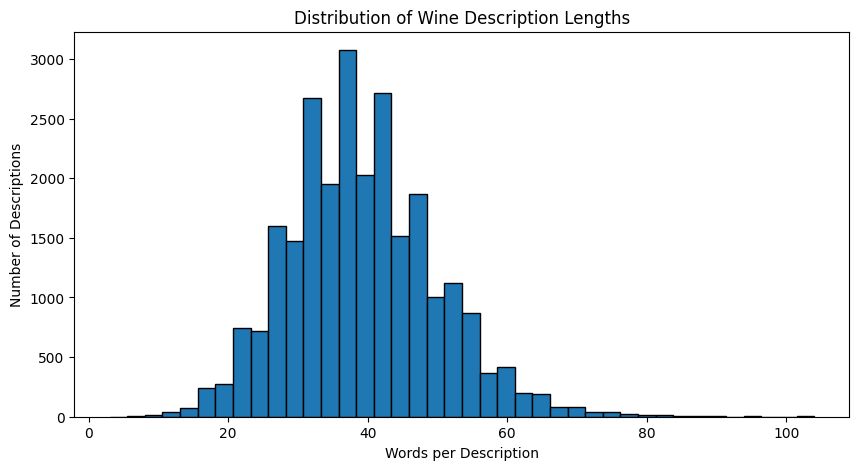

count    25496.000000
mean        39.148298
std         10.599575
min          3.000000
25%         32.000000
50%         38.000000
75%         45.000000
max        104.000000
Name: word_count, dtype: float64


In [ ]:
df_filtered["word_count"] = (
    df_filtered["description"].str.split().str.len()
)

plt.figure(figsize=(10, 5))

plt.hist(df_filtered["word_count"], bins=40, edgecolor="black")

plt.xlabel("Words per Description")
plt.ylabel("Number of Descriptions")
plt.title("Distribution of Wine Description Lengths")

plt.show()

print(df_filtered["word_count"].describe())


In [ ]:
length_summary = (
    df_filtered
    .groupby("style_group")["word_count"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

display(length_summary.head(20))


,count,mean,median,std
style_group,,,,
Chardonnay,11760,38.350850,38.0,10.891468
Sparkling,4559,39.416977,38.0,10.039898
Sangiovese,3501,40.479006,40.0,9.515337
White Blend,2443,39.933279,39.0,10.679113
Aromatic White,2352,39.036565,38.0,11.022248
Fortified/Dessert,881,41.236095,40.0,11.162482


The number of words to describe a wine seems pretty even across all 6 wine groups.

Now we explore the most common English word to describle the flavor of wine.

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=3
)

X_counts = vectorizer.fit_transform(
    df_filtered["description"]
)

words = vectorizer.get_feature_names_out()

frequencies = np.asarray(
    X_counts.sum(axis=0)
).ravel()

word_freq = pd.DataFrame({
    "word": words,
    "count": frequencies
}).sort_values("count", ascending=False)

display(word_freq.head(20))


,word,count
978,wine,15423
352,flavors,11753
383,fruit,8962
26,acidity,8619
56,aromas,7887
634,palate,7804
49,apple,6635
344,finish,6259
744,ripe,5437
275,drink,5033


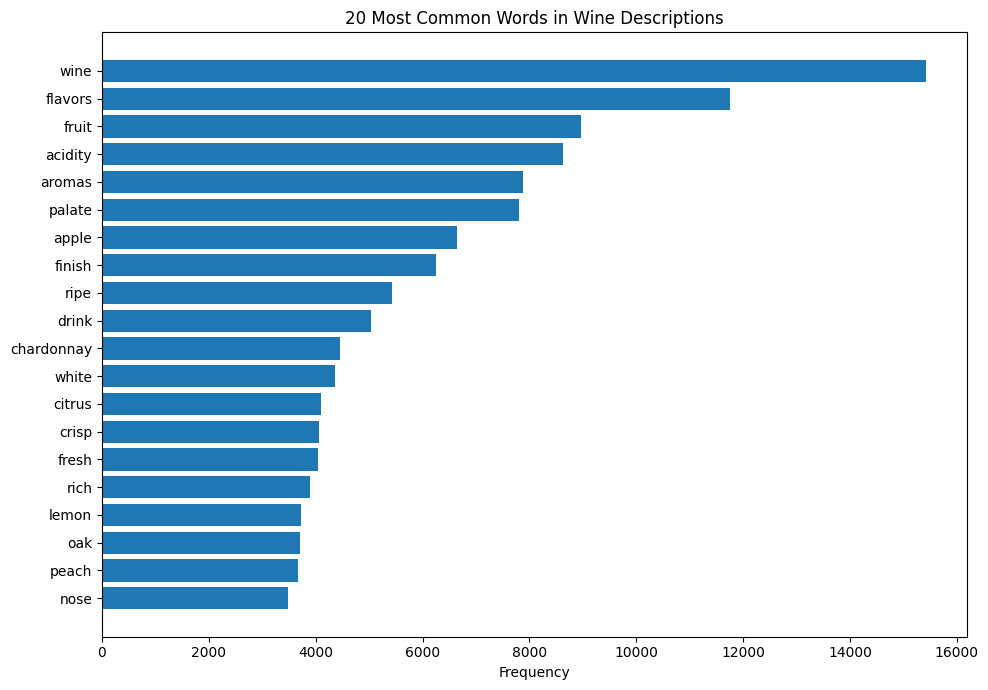

In [ ]:
top_words = word_freq.head(20).sort_values("count")

plt.figure(figsize=(10, 7))

plt.barh(top_words["word"], top_words["count"])

plt.xlabel("Frequency")
plt.title("20 Most Common Words in Wine Descriptions")

plt.tight_layout()
plt.show()


Now we do the same with two word combos

In [ ]:
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    min_df=3,
    max_features=1000
)

X_bigrams = bigram_vectorizer.fit_transform(
    df_filtered["description"]
)

bigram_freq = pd.DataFrame({
    "bigram": bigram_vectorizer.get_feature_names_out(),
    "count": np.asarray(
        X_bigrams.sum(axis=0)
    ).ravel()
}).sort_values("count", ascending=False)

display(bigram_freq.head(20))


,bigram,count
437,fruit flavors,1288
662,palate offers,1096
475,green apple,1016
732,ready drink,988
899,tropical fruit,955
836,stone fruit,875
182,buttered toast,791
145,black cherry,776
269,crisp acidity,715
929,white peach,704


Now we explore what word is associated with what wine to see what words tends to describe what wine

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    binary=True,
    min_df=5,
    max_df=0.95
)

X = vectorizer.fit_transform(df_filtered["description"])

terms = vectorizer.get_feature_names_out()

overall_rate = np.asarray(X.mean(axis=0)).ravel()

top_varieties = variety_counts.head(10).index

results = []

for variety in top_varieties:

    mask = (df_filtered["variety"] == variety).to_numpy()

    variety_rate = np.asarray(
        X[mask].mean(axis=0)
    ).ravel()

    lift = variety_rate / (overall_rate + 1e-10)

    valid = variety_rate >= 0.10

    top_indices = np.argsort(
        np.where(valid, lift, -np.inf)
    )[-10:][::-1]

    for idx in top_indices:
        if not valid[idx]:
            continue

        results.append({
            "variety": variety,
            "word": terms[idx],
            "variety_frequency": variety_rate[idx],
            "lift": lift[idx]
        })

distinctive_words = pd.DataFrame(results)

display(distinctive_words)


,variety,word,variety_frequency,lift
0,Chardonnay,pineapple,0.135200,1.780500
1,Chardonnay,oak,0.227346,1.705833
2,Chardonnay,chardonnay,0.273547,1.604407
3,Chardonnay,toast,0.145580,1.584167
4,Chardonnay,tropical,0.111121,1.559235
...,...,...,...,...
95,Moscato,honey,0.337989,5.138559
96,Moscato,sweet,0.536313,4.343657
97,Moscato,pair,0.106145,4.282088
98,Moscato,blossom,0.100559,3.981124


##Second EDA

In [ ]:
df_new = pd.read_parquet("/content/processed_reviews.parquet")

In [ ]:
df_new.shape

(129970, 19)

In [ ]:
df_new.head(10)

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery,description_masked,tokens_raw,tokens,clean_text,clean_designation
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,None,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,"Aromas include tropical fruit, broom, brimston...","[aroma, include, tropical, fruit, broom, brims...","[aroma, include, tropical, fruit, broom, brims...",aroma include tropical fruit broom brimstone d...,vulkà
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,None,None,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,"This is ripe and fruity, a wine that is smooth...","[ripe, fruity, wine, smooth, still, structured...","[ripe, fruity, smooth, still, structured, firm...",ripe fruity smooth still structured firm tanni...,avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",None,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,"Tart and snappy, the flavors of lime flesh and...","[tart, snappy, flavor, lime, flesh, rind, domi...","[tart, snappy, lime, flesh, rind, dominate, gr...",tart snappy lime flesh rind dominate green pin...,
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,None,Alexander Peartree,None,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,"Pineapple rind, lemon pith and orange blossom ...","[pineapple, rind, lemon, pith, orange, blossom...","[pineapple, rind, lemon, pith, orange, blossom...",pineapple rind lemon pith orange blossom start...,reserve late harvest
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,"Much like the regular bottling from 2012, this...","[much, like, regular, bottling, come, across, ...","[much, like, regular, bottling, come, across, ...",much like regular bottling come across rather ...,vintner reserve wild child block
5,5,Spain,Blackberry and raspberry aromas show a typical...,Ars In Vitro,87,15.0,Northern Spain,Navarra,None,Michael Schachner,@wineschach,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Tempranillo-Merlot,Tandem,Blackberry and raspberry aromas show a typical...,"[blackberry, raspberry, aroma, show, typical, ...","[blackberry, raspberry, aroma, typical, navarr...",blackberry raspberry aroma typical navarran wh...,ar vitro
6,6,Italy,"Here's a bright, informal red that opens with ...",Belsito,87,16.0,Sicily & Sardinia,Vittoria,None,Kerin O’Keefe,@kerinokeefe,Terre di Giurfo 2013 Belsito Frappato (Vittoria),Frappato,Terre di Giurfo,"Here's a bright, informal red that opens with ...","[bright, informal, red, open, aroma, candied, ...","[bright, informal, red, open, aroma, candied, ...",bright informal red open aroma candied berry w...,belsito
7,7,France,This dry and restrained wine offers spice in p...,None,87,24.0,Alsace,Alsace,None,Roger Voss,@vossroger,Trimbach 2012 Gewurztraminer (Alsace),Gewürztraminer,Trimbach,This dry and restrained wine offers spice in p...,"[dry, restrained, wine, offer, spice, profusio...","[dry, restrained, offer, spice, profusion, bal...",dry restrained offer spice profusion balanced ...,
8,8,Germany,Savory dried thyme notes accent sunnier flavor...,Shine,87,12.0,Rheinhessen,None,None,Anna Lee C. Iijima,None,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...,Gewürztraminer,Heinz Eifel,Savory dried thyme notes accent sunnier flavor...,"[savory, dried, thyme, note, accent, sunnier, ...","[savory, dried, thyme, accent, sunnier, preser...",savory dried thyme accent sunnier preserved pe...,s

Remove all wines with less than 500 observations

In [ ]:
variety_counts = df_new["variety"].value_counts()

# Keep varieties with at least 500 observations
valid_varieties = variety_counts[variety_counts >= 500].index

# Filter dataset
df_new = df_new[df_new["variety"].isin(valid_varieties)].copy()

# Reset index
df_new.reset_index(drop=True, inplace=True)

# Display results
print(f"Remaining observations: {len(df_new):,}")
print(f"Remaining wine varieties: {df_new['variety'].nunique()}")

Remaining observations: 111,797
Remaining wine varieties: 40


In [ ]:
variety_summary = (
    df_new["variety"]
    .value_counts()
    .rename_axis("Variety")
    .reset_index(name="Observations")
)

display(variety_summary)

,Variety,Observations
0,Pinot Noir,13272
1,Chardonnay,11753
2,Cabernet Sauvignon,9472
3,Red Blend,8946
4,Bordeaux-style Red Blend,6915
5,Riesling,5189
6,Sauvignon Blanc,4967
7,Syrah,4142
8,Rosé,3564
9,Merlot,3102


In [ ]:
# Count words in each masked description
df_new["review_length"] = (
    df_new["description_masked"]
    .fillna("")
    .str.split()
    .str.len()
)

# Summary statistics
print("Review Length Statistics:")
print(df_new["review_length"].describe().round(2))

print(f"\nMedian review length: {df_new['review_length'].median():.0f} words")
print(f"Mean review length: {df_new['review_length'].mean():.2f} words")
print(f"90th percentile: {df_new['review_length'].quantile(0.90):.0f} words")
print(f"95th percentile: {df_new['review_length'].quantile(0.95):.0f} words")

Review Length Statistics:
count    111797.00
mean         40.30
std          11.19
min           3.00
25%          33.00
50%          39.00
75%          47.00
max         135.00
Name: review_length, dtype: float64

Median review length: 39 words
Mean review length: 40.30 words
90th percentile: 55 words
95th percentile: 60 words


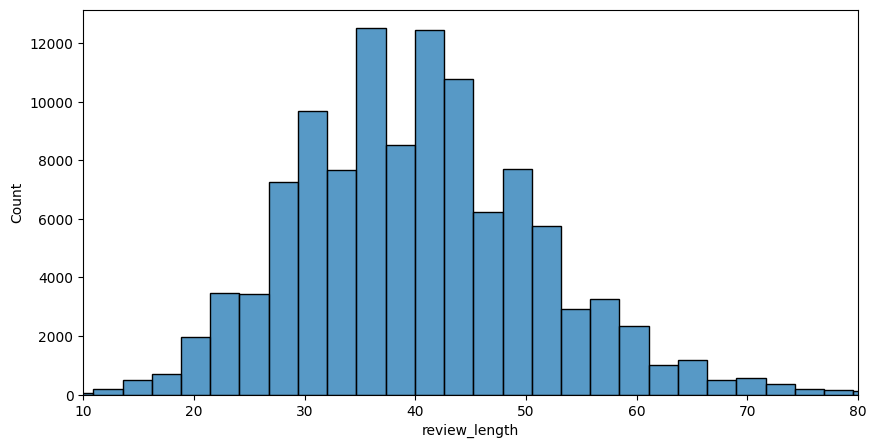

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df_new["review_length"],
    bins=50
)

plt.xlim(10, 80)

plt.show()

Most common words

In [ ]:
from collections import Counter

# Count words from cleaned, masked reviews
word_counts = Counter(
    word
    for tokens in df_new["tokens"]
    for word in tokens
)

# Top 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

display(top_words)

,Word,Frequency
0,fruit,50702
1,aroma,32770
2,finish,32204
3,acidity,29744
4,tannin,29353
5,cherry,28327
6,ripe,23660
7,black,22433
8,spice,18985
9,red,16334


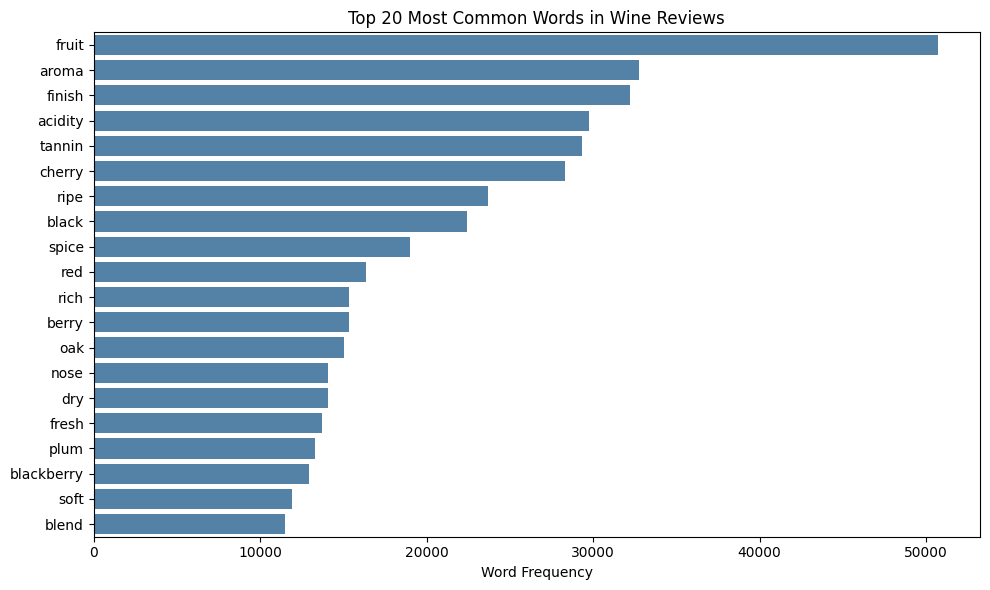

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    color="steelblue"
)

plt.title("Top 20 Most Common Words in Wine Reviews")
plt.xlabel("Word Frequency")
plt.ylabel("")

plt.tight_layout()
plt.show()

These singular words may be part of a two word or three word descriptor like black cherry or red apple, etc.

Now moving on to weird words

In [ ]:
!pip -q install wordfreq

In [ ]:
from wordfreq import zipf_frequency

word_summary = pd.DataFrame(
    word_counts.items(),
    columns=["Word", "Frequency"]
)

# General English frequency score
word_summary["English_Frequency"] = (
    word_summary["Word"].apply(
        lambda word: zipf_frequency(word, "en")
    )
)

# Keep words appearing at least 20 times
word_summary = word_summary[
    (word_summary["Frequency"] >= 20) &
    (word_summary["Word"].str.len() >= 5)
].copy()

# Rank uncommon English words
bizarre_words = word_summary.sort_values(
    ["English_Frequency", "Frequency"],
    ascending=[True, False]
)

display(bizarre_words.head(30))

,Word,Frequency,English_Frequency
270,midpalate,1291,0.0
3150,resiny,499,0.0
551,raisiny,413,0.0
1061,briary,402,0.0
1006,aromatically,380,0.0
1226,mouthfilling,352,0.0
4072,superripe,328,0.0
2799,perlage,259,0.0
3654,stemmy,235,0.0
225,woodspice,234,0.0


In [ ]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 1000)

# Pick a word from the unusual word table
word = bizarre_words.iloc[0]["Word"]

# Find reviews containing the word
matches = df_new[
    df_new["tokens"].apply(lambda tokens: word in tokens)
]

print(f"Word: {word}")
print(f"Occurrences: {word_counts[word]:,}")

display(
    matches[
        ["variety", "description_masked"]
    ].sample(
        min(10, len(matches)),
        random_state=42
    )
)

Word: midpalate
Occurrences: 1,291


,variety,description_masked
98854,Syrah,"Pure purple aromas of boysenberry jam and Concord grapes swirl amidst melted dark chocolate, maple-drizzled bacon and touches of beef carpaccio on the nose of this bottling from a coveted vineyard. Starting with strong blueberry and blackberry fruit, the palate then sizzles with acidity through the fine-grained tannic structure. The midpalate shows meaty depth with roasting herbs and minty lift throughout."
104263,Chardonnay,"This is a lightly style wine but extremely vivacious and sexy, with cut red varietyname, mandarin orange skin, ripe nectarine and lightly honeyed Gravenstein varietyname on the nose. It's clean, crisp and focused on the palate, where lime zest, limestone and a touch of buttered pear in the midpalate makes for a complete and balanced sip."
42947,Riesling,"One of the consistently finest Rieslings from the state, this is technically off dry, but feels dry given its exceptional acidity. Elegant citrus and floral aromas introduce a dense, textural midpalate. A showcase of style and panache, its layered citrus and stone fruits bring both skin and flesh flavors into focus."
8454,Riesling,"Chalk and slate notes juxtapose fragrant, sweet-tart tangerine, lime and lemon on the nose and palate of this laser-edged kabinett. A kiss of honey gives the midpalate just a touch of sweetness that lingers long on the finish."
6697,Grüner Veltliner,"Subtle but unmistakable white pepper flashes through this slender, lemony but oh-so-savory wine. Notions of ripe pear enter on the midpalate which comes across as complete, harmonious and long."
11619,Syrah,"Ripe and plump blackberries shine through in a showcase of fruit purity, lifted by dried fennel, hot black gravel, peppercorns, toasted sesame and soy. There is tremendous structure and acidity on the sip, with black pepper and black-sesame nuance plus juicy boysenberry character to the midpalate."
41416,Syrah,"Co-fermented with a small quantity of varietyname, this varietyname was aged in 100% new oak. It's flashy and completely satisfying to drink now. Starts a little soft and dry, then explodes midpalate into a burst of cherry and raspberry fruit, with creamy, caramelized notes. The finish is long-lasting and elegant."
93611,Zinfandel,"This is a big, oaky, brawny and tannic version of the variety, generous in brown sugar and blackberry and plum jam. A piquant seasoning of peppercorn dots the midpalate and finish."
67036,Gewürztraminer,"This solid, fruity, generous wine pushes bold flavors of white peach and varietyname into a rich midpalate. Highlights of lemon verbena and hints of mint accompany the expected floral scents and lightly soapy character of this distinctive grape. Drink this over the next two years while its freshness is at its best."
4706,Sauvignon Blanc,"The restrained aromatics of wet grass and gentle smoke are the only reminders that this is varietyname. This is lightyears removed from the pungently fragrant style that has made the variety so popular—here, it comes in a grown-up, classy guise with wonderfully judged balance and a lovely midpalate weight."
